In [1]:
# ============================================================
# CELL 1: IMPORTING LIBRARIES
# ============================================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import joblib

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier

from sklearn.neighbors import KNeighborsClassifier

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

import joblib

import warnings

warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

print("All libraries imported successfully✅.")

All libraries imported successfully✅.


In [2]:
# ============================================================
# CELL 2: LOAD DATASET
# ============================================================
file_path = "C://Users//ashiq//Downloads//organic_farming_suitability_1000_source_calibrated.csv"

df = pd.read_csv(
    file_path
)

print("Dataset loaded successfully.")

print(
    "Number of rows:",
    df.shape[0]
)

print(
    "Number of columns:",
    df.shape[1]
)


Dataset loaded successfully.
Number of rows: 1000
Number of columns: 24


In [3]:
# ============================================================
# CELL 3: BASIC DATASET CHECKING
# ============================================================

print("First 5 row:")
print()
display(
    df.head()
)

#check the 5 rows
print("Last 5 row:")
print()

display(
    df.tail()
)

# Check dataset shape
print("Dataset Shape")
print(
    "Rows:",
    df.shape[0]
)

print(
    "Columns:",
    df.shape[1]
)

# Display all column names

print("Column Names:")
print()

for column in df.columns:
    print(column)

# Display data types
print("Data Types:")
print()

print(
    df.dtypes
)

# Dataset information
print("Dataset Information:")
print()

df.info()

# Statistical summary
print("Statistical Summary:")
print()

display(
    df.describe()
)

# Check categorical columns
print("Categorical Columns:")

categorical_columns = df.select_dtypes(
    include=["object"]
).columns

for column in categorical_columns:
    print(column)

# Check numerical columns
print("Numerical Columns:")

numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns

for column in numerical_columns:
    print(column)

First 5 row:



,Sample_ID,State,Soil_Type,Crop,pH,Organic_Carbon_pct,Available_N_kg_ha,Available_P_kg_ha,Available_K_kg_ha,Available_S_mg_kg,...,Available_B_mg_kg,EC_dS_m,Annual_Rainfall_mm,Mean_Temperature_C,Soil_Moisture_pct,Previous_Fertilizer_Usage,Previous_Pesticide_Usage,Years_Chemical_Input,Suitability_Score,Organic_Farming_Suitability
0,OF-0001,Haryana,Sandy,Tomato,6.13,0.411,80.0,65.2,266.9,15.71,...,0.29,0.191,954.2,26.5,17.9,Mixed,Low,0,39.1,Not Suitable
1,OF-0002,Andhra Pradesh,Loamy,Sugarcane,7.58,0.826,187.8,29.4,131.5,13.64,...,0.65,0.652,841.9,30.7,33.6,Chemical,Moderate,8,53.0,Not Suitable
2,OF-0003,Karnataka,Loamy,Pulses,6.00,0.684,353.4,3.0,351.5,20.35,...,0.48,0.317,562.3,23.0,30.6,Chemical,Moderate,12,45.2,Not Suitable
3,OF-0004,Madhya Pradesh,Red,Pulses,6.69,0.706,200.3,39.0,61.7,10.96,...,2.51,0.323,741.1,26.8,33.5,Chemical,Moderate,8,44.7,Not Suitable
4,OF-0005,Madhya Pradesh,Red,Sugarcane,6.46,1.564,181.3,11.7,411.4,14.66,...,0.65,0.512,870.0,25.0,24.3,Chemical,High,2,52.6,Not Suitable


Last 5 row:



,Sample_ID,State,Soil_Type,Crop,pH,Organic_Carbon_pct,Available_N_kg_ha,Available_P_kg_ha,Available_K_kg_ha,Available_S_mg_kg,...,Available_B_mg_kg,EC_dS_m,Annual_Rainfall_mm,Mean_Temperature_C,Soil_Moisture_pct,Previous_Fertilizer_Usage,Previous_Pesticide_Usage,Years_Chemical_Input,Suitability_Score,Organic_Farming_Suitability
995,OF-0996,Karnataka,Laterite,Soybean,6.02,0.469,367.3,3.0,472.3,6.01,...,0.48,0.671,1260.1,26.7,25.6,Mixed,Moderate,0,43.7,Not Suitable
996,OF-0997,Rajasthan,Loamy,Rice,7.47,1.900,181.2,40.5,490.6,27.51,...,0.49,1.059,504.7,32.9,41.9,Chemical,Moderate,4,81.6,Suitable
997,OF-0998,Maharashtra,Laterite,Potato,6.68,0.631,252.6,3.0,373.7,15.84,...,0.41,0.450,789.1,25.7,32.2,Organic,High,1,46.4,Not Suitable
998,OF-0999,Assam,Black,Sugarcane,5.01,0.541,86.9,35.7,341.8,18.22,...,0.78,0.239,704.7,24.5,16.4,Chemical,Moderate,7,20.3,Not Suitable
999,OF-1000,Rajasthan,Laterite,Mustard,5.30,0.658,366.7,24.3,223.3,13.23,...,0.40,0.500,1314.0,25.4,37.9,Mixed,Moderate,3,22.6,Not Suitable


Dataset Shape
Rows: 1000
Columns: 24
Column Names:

Sample_ID
State
Soil_Type
Crop
pH
Organic_Carbon_pct
Available_N_kg_ha
Available_P_kg_ha
Available_K_kg_ha
Available_S_mg_kg
Available_Zn_mg_kg
Available_Fe_mg_kg
Available_Mn_mg_kg
Available_Cu_mg_kg
Available_B_mg_kg
EC_dS_m
Annual_Rainfall_mm
Mean_Temperature_C
Soil_Moisture_pct
Previous_Fertilizer_Usage
Previous_Pesticide_Usage
Years_Chemical_Input
Suitability_Score
Organic_Farming_Suitability
Data Types:

Sample_ID                       object
State                           object
Soil_Type                       object
Crop                            object
pH                             float64
Organic_Carbon_pct             float64
Available_N_kg_ha              float64
Available_P_kg_ha              float64
Available_K_kg_ha              float64
Available_S_mg_kg              float64
Available_Zn_mg_kg             float64
Available_Fe_mg_kg             float64
Available_Mn_mg_kg             float64
Available_Cu_mg_kg         

,pH,Organic_Carbon_pct,Available_N_kg_ha,Available_P_kg_ha,Available_K_kg_ha,Available_S_mg_kg,Available_Zn_mg_kg,Available_Fe_mg_kg,Available_Mn_mg_kg,Available_Cu_mg_kg,Available_B_mg_kg,EC_dS_m,Annual_Rainfall_mm,Mean_Temperature_C,Soil_Moisture_pct,Years_Chemical_Input,Suitability_Score
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000
mean,6.915940,0.724501,259.016700,29.549400,254.25270,15.801290,0.785150,20.480830,9.191230,0.774470,0.664450,0.416374,958.61930,26.989700,28.409200,5.234000,52.279100
std,0.754045,0.346696,91.347824,16.859065,126.79943,6.615834,0.366406,12.802683,5.361124,0.385222,0.360343,0.245273,437.40239,3.448027,8.941545,4.037021,13.259376
min,4.800000,0.189000,80.000000,3.000000,40.00000,3.000000,0.150000,2.990000,1.440000,0.170000,0.130000,0.050000,180.00000,17.000000,8.000000,0.000000,4.500000
25%,6.400000,0.481000,194.075000,16.475000,165.70000,11.282500,0.530000,11.915000,5.490000,0.517500,0.430000,0.247750,646.12500,24.575000,22.800000,2.000000,43.575000
50%,6.925000,0.653500,257.300000,29.100000,242.35000,15.540000,0.710000,17.335000,7.765000,0.695000,0.580000,0.357000,928.90000,26.900000,28.400000,4.000000,52.750000
75%,7.420000,0.877250,315.825000,40.825000,345.92500,20.257500,0.960000,25.312500,11.625000,0.930000,0.800000,0.526250,1255.67500,29.400000,34.325000,6.000000,60.400000
max,9.190000,2.500000,588.100000,86.300000,653.20000,39.060000,4.000000,80.000000,40.000000,4.000000,2.730000,1.926000,2240.60000,36.000000,55.000000,15.000000,89.300000


Categorical Columns:
Sample_ID
State
Soil_Type
Crop
Previous_Fertilizer_Usage
Previous_Pesticide_Usage
Organic_Farming_Suitability
Numerical Columns:
pH
Organic_Carbon_pct
Available_N_kg_ha
Available_P_kg_ha
Available_K_kg_ha
Available_S_mg_kg
Available_Zn_mg_kg
Available_Fe_mg_kg
Available_Mn_mg_kg
Available_Cu_mg_kg
Available_B_mg_kg
EC_dS_m
Annual_Rainfall_mm
Mean_Temperature_C
Soil_Moisture_pct
Years_Chemical_Input
Suitability_Score


In [4]:
# ============================================================
# CELL 4: DATA CLEANING
# ============================================================

# Remove extra spaces from column names

df.columns = df.columns.str.strip()

print("Column names cleaned.")

print(
    df.columns.tolist()
)

# Check missing values
print("Missing Values:")
print()

missing_values = df.isnull().sum()

display(
    missing_values
)

# Calculate percentage of missing values
missing_percentage = (
    df.isnull().sum()
    / len(df)
) * 100

missing_table = pd.DataFrame(
    {
        "Missing_Count": df.isnull().sum(),
        "Missing_Percentage": missing_percentage
    }
)

display(
    missing_table
)

# Check duplicate rows
duplicate_count = df.duplicated().sum()

print(
    "Number of duplicate rows:",
    duplicate_count
)

# Remove duplicate rows
if duplicate_count > 0:

    df = df.drop_duplicates()

    print(
        "Duplicate rows removed."
    )

else:

    print(
        "No duplicate rows found."
    )

# Check duplicate Sample_ID values
duplicate_ids = df["Sample_ID"].duplicated().sum()

print(
    "Duplicate Sample_ID values:",
    duplicate_ids
)

# Check unique values of target variable
print(
    "Target Variable Values:"
)

print(
    df["Organic_Farming_Suitability"].unique()
)

# Check target distribution
print(
    df["Organic_Farming_Suitability"].value_counts()
)

# Check whether numerical values contain impossible NaN or infinity
print(
    "Infinite values:"
)

numeric_df = df.select_dtypes(
    include=["number"]
)

print(
    np.isinf(numeric_df).sum().sum()
)

# Replace infinite values with NaN
df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Infinite values handled."
)

# Final dataset check
print("Final dataset shape after cleaning:")

print(
    df.shape
)

Column names cleaned.
['Sample_ID', 'State', 'Soil_Type', 'Crop', 'pH', 'Organic_Carbon_pct', 'Available_N_kg_ha', 'Available_P_kg_ha', 'Available_K_kg_ha', 'Available_S_mg_kg', 'Available_Zn_mg_kg', 'Available_Fe_mg_kg', 'Available_Mn_mg_kg', 'Available_Cu_mg_kg', 'Available_B_mg_kg', 'EC_dS_m', 'Annual_Rainfall_mm', 'Mean_Temperature_C', 'Soil_Moisture_pct', 'Previous_Fertilizer_Usage', 'Previous_Pesticide_Usage', 'Years_Chemical_Input', 'Suitability_Score', 'Organic_Farming_Suitability']
Missing Values:



Sample_ID                      0
State                          0
Soil_Type                      0
Crop                           0
pH                             0
Organic_Carbon_pct             0
Available_N_kg_ha              0
Available_P_kg_ha              0
Available_K_kg_ha              0
Available_S_mg_kg              0
Available_Zn_mg_kg             0
Available_Fe_mg_kg             0
Available_Mn_mg_kg             0
Available_Cu_mg_kg             0
Available_B_mg_kg              0
EC_dS_m                        0
Annual_Rainfall_mm             0
Mean_Temperature_C             0
Soil_Moisture_pct              0
Previous_Fertilizer_Usage      0
Previous_Pesticide_Usage       0
Years_Chemical_Input           0
Suitability_Score              0
Organic_Farming_Suitability    0
dtype: int64

,Missing_Count,Missing_Percentage
Sample_ID,0,0.0
State,0,0.0
Soil_Type,0,0.0
Crop,0,0.0
pH,0,0.0
Organic_Carbon_pct,0,0.0
Available_N_kg_ha,0,0.0
Available_P_kg_ha,0,0.0
Available_K_kg_ha,0,0.0
Available_S_mg_kg,0,0.0


Number of duplicate rows: 0
No duplicate rows found.
Duplicate Sample_ID values: 0
Target Variable Values:
['Not Suitable' 'Suitable']
Organic_Farming_Suitability
Not Suitable    577
Suitable        423
Name: count, dtype: int64
Infinite values:
0
Infinite values handled.
Final dataset shape after cleaning:
(1000, 24)


In [5]:
# ============================================================
# CELL 5: EXPLORATORY DATA ANALYSIS
# ============================================================

print(
    "Exploratory Data Analysis"
)

print(
    "Total records:",
    len(df)
)

print(
    "Total features:",
    len(df.columns)
)

Exploratory Data Analysis
Total records: 1000
Total features: 24


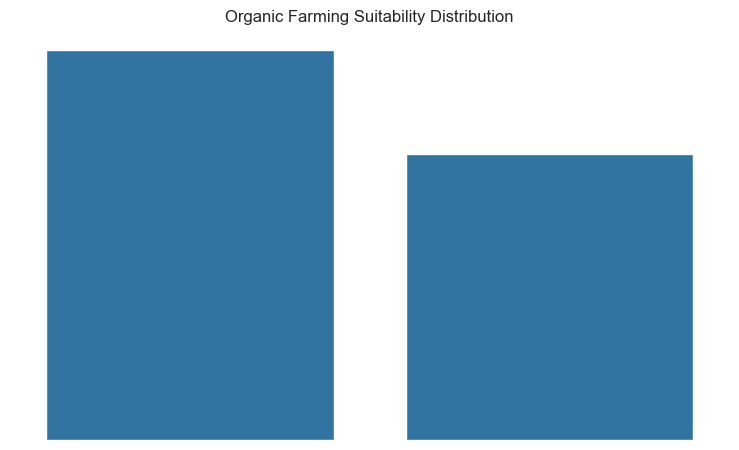

In [6]:
# Target variable distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Organic_Farming_Suitability"
)

plt.title("Organic Farming Suitability Distribution")
plt.xlabel("Organic Farming Suitability")
plt.ylabel("Number of Records")

plt.tight_layout()

# Save image at 404 DPI
plt.savefig(
    "organic_farming_suitability_distribution.png",
    dpi=404,
    bbox_inches="tight"
)
plt.axis(False)
plt.show()

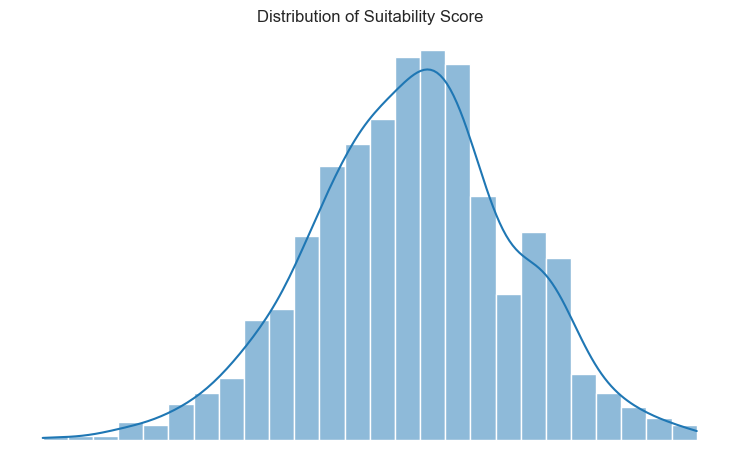

In [7]:
# Distribution of Suitability Score

plt.figure(
    figsize=(8, 5)
)

sns.histplot(
    data=df,
    x="Suitability_Score",
    kde=True
)

plt.title(
    "Distribution of Suitability Score"
)

plt.xlabel(
    "Suitability Score"
)

plt.ylabel(
    "Frequency"
)

plt.tight_layout()

plt.savefig(
    "suitability_score_distribution.png",
    dpi=404,
    bbox_inches="tight"
)
plt.axis(False)
plt.show()

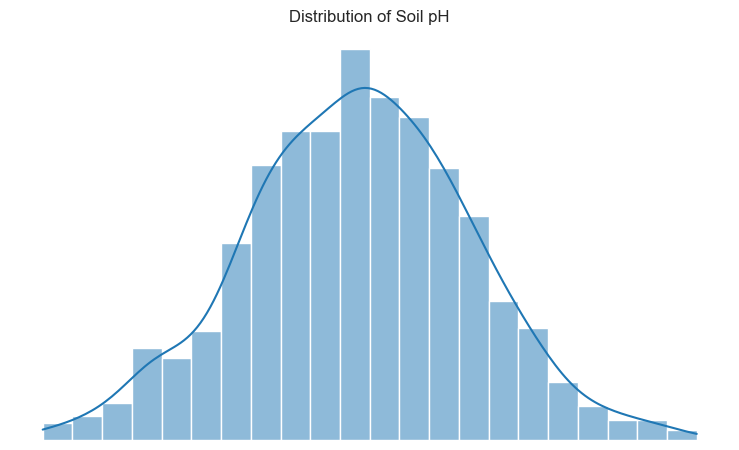

In [8]:
# Distribution of Soil pH

plt.figure(
    figsize=(8, 5)
)

sns.histplot(
    data=df,
    x="pH",
    kde=True
)

plt.title(
    "Distribution of Soil pH"
)

plt.xlabel(
    "Soil pH"
)

plt.ylabel(
    "Frequency"
)

plt.tight_layout()

plt.savefig(
    "soil_pH_distribution.png",
    dpi=404,
    bbox_inches="tight"
)
plt.axis(False)
plt.show()

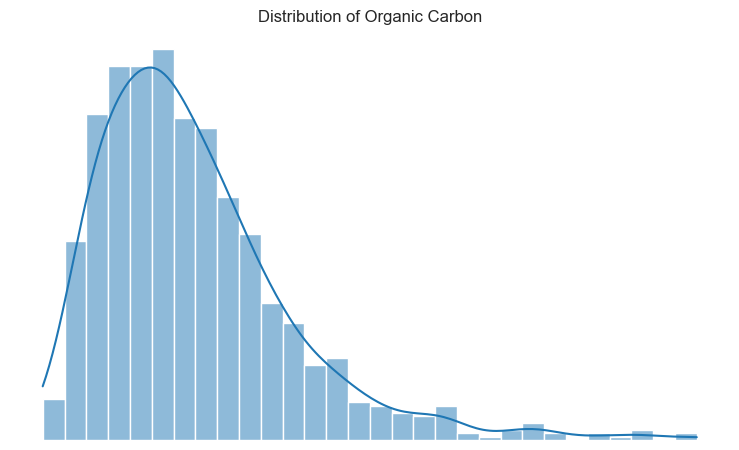

In [9]:
plt.figure(
    figsize=(8, 5)
)

sns.histplot(
    data=df,
    x="Organic_Carbon_pct",
    kde=True
)

plt.title(
    "Distribution of Organic Carbon"
)

plt.xlabel(
    "Organic Carbon (%)"
)

plt.ylabel(
    "Frequency"
)

plt.tight_layout()

plt.savefig(
    "organic_carbon_distribution.png",
    dpi=404,
    bbox_inches="tight"
)
plt.axis(False)
plt.show()

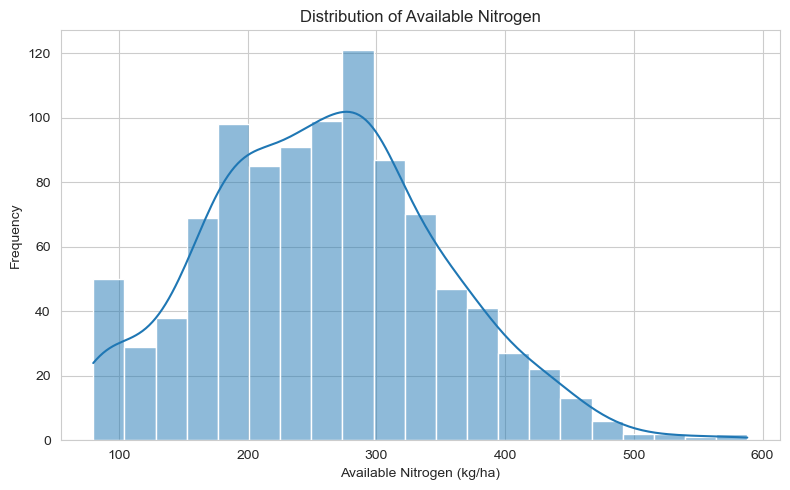

In [10]:
plt.figure(
    figsize=(8, 5)
)

sns.histplot(
    data=df,
    x="Available_N_kg_ha",
    kde=True
)

plt.title(
    "Distribution of Available Nitrogen"
)

plt.xlabel(
    "Available Nitrogen (kg/ha)"
)

plt.ylabel(
    "Frequency"
)

plt.tight_layout()

plt.show()

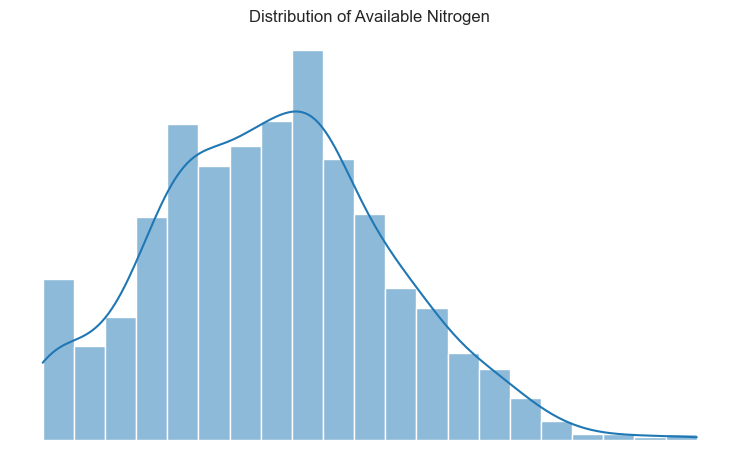

In [11]:
plt.figure(
    figsize=(8, 5)
)

sns.histplot(
    data=df,
    x="Available_N_kg_ha",
    kde=True
)

plt.title(
    "Distribution of Available Nitrogen"
)

plt.xlabel(
    "Available Nitrogen (kg/ha)"
)

plt.ylabel(
    "Frequency"
)

plt.tight_layout()

plt.savefig(
    "available_nitrogen_distribution.png",
    dpi=404,
    bbox_inches="tight"
)
plt.axis(False)
plt.show()

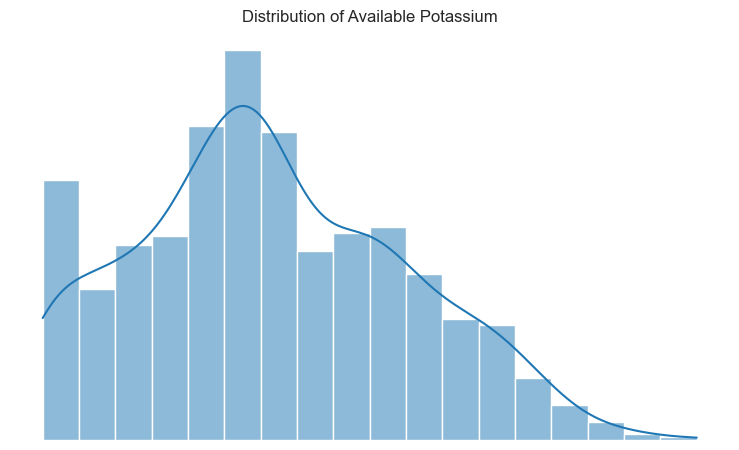

In [12]:
plt.figure(
    figsize=(8, 5)
)

sns.histplot(
    data=df,
    x="Available_K_kg_ha",
    kde=True
)

plt.title(
    "Distribution of Available Potassium"
)

plt.xlabel(
    "Available Potassium (kg/ha)"
)

plt.ylabel(
    "Frequency"
)

plt.tight_layout()

plt.savefig(
    "available_potassium_distribution.png",
    dpi=404,
    bbox_inches="tight"
)
plt.axis(False)
plt.show()

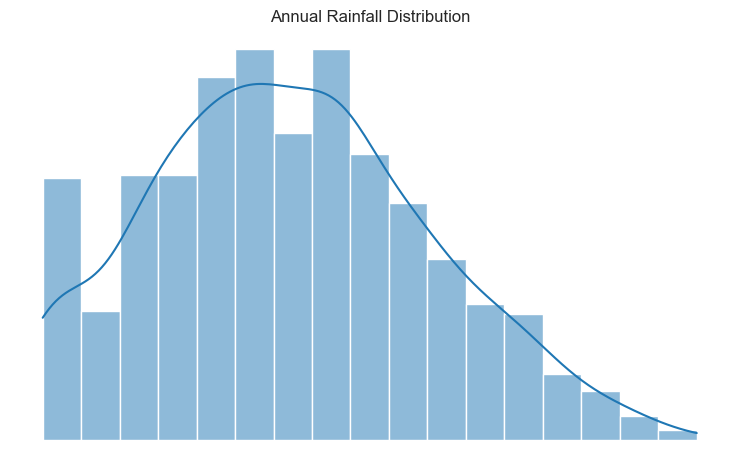

In [13]:
plt.figure(
    figsize=(8, 5)
)

sns.histplot(
    data=df,
    x="Annual_Rainfall_mm",
    kde=True
)

plt.title(
    "Annual Rainfall Distribution"
)

plt.xlabel(
    "Annual Rainfall (mm)"
)

plt.ylabel(
    "Frequency"
)

plt.tight_layout()

plt.savefig(
    "annual_rainfall_distribution.png",
    dpi=404,
    bbox_inches="tight"
)
plt.axis(False)
plt.show()

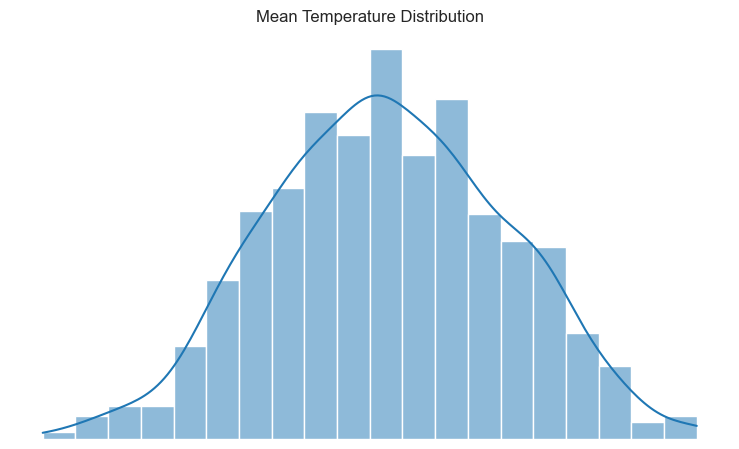

In [14]:
plt.figure(
    figsize=(8, 5)
)

sns.histplot(
    data=df,
    x="Mean_Temperature_C",
    kde=True
)

plt.title(
    "Mean Temperature Distribution"
)

plt.xlabel(
    "Mean Temperature (°C)"
)

plt.ylabel(
    "Frequency"
)

plt.tight_layout()

plt.savefig(
    "mean_temperature_distribution.png",
    dpi=404,
    bbox_inches="tight"
)
plt.axis(False)
plt.show()

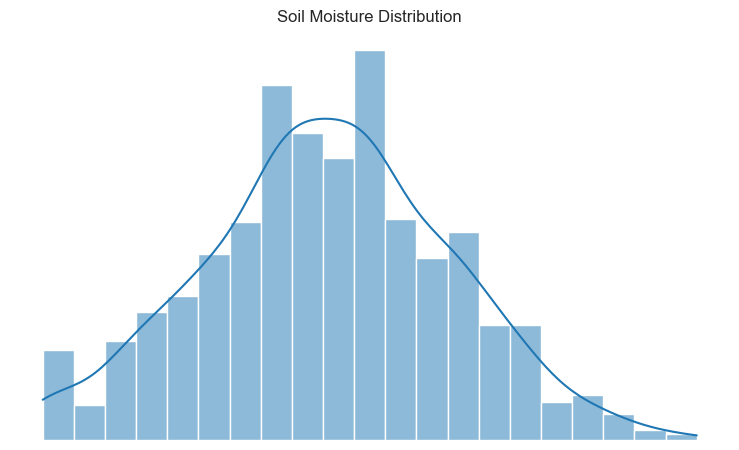

In [15]:
plt.figure(
    figsize=(8, 5)
)

sns.histplot(
    data=df,
    x="Soil_Moisture_pct",
    kde=True
)

plt.title(
    "Soil Moisture Distribution"
)

plt.xlabel(
    "Soil Moisture (%)"
)

plt.ylabel(
    "Frequency"
)

plt.tight_layout()

plt.savefig(
    "soil_moisture_distribution.png",
    dpi=404,
    bbox_inches="tight"
)
plt.axis(False)
plt.show()

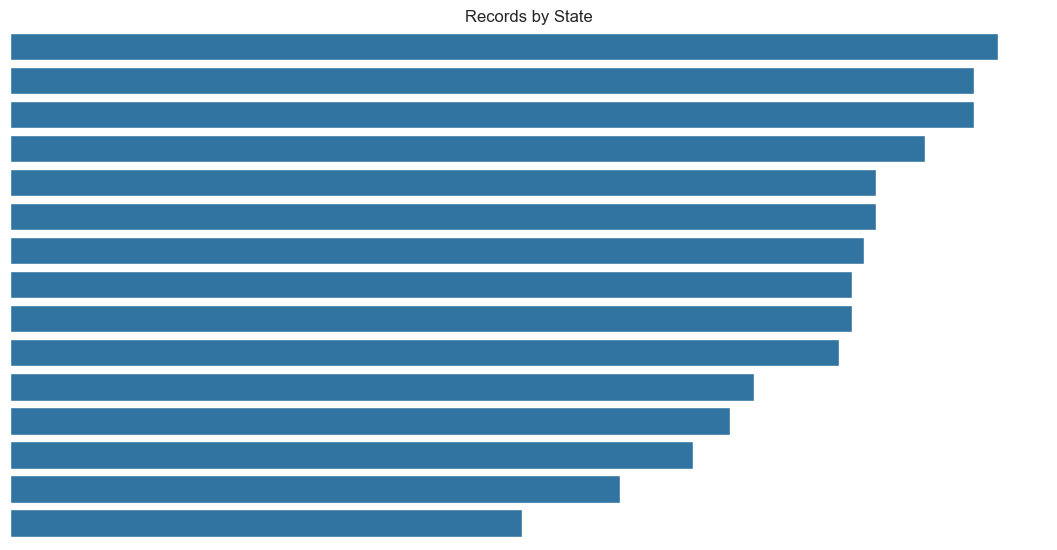

In [16]:
plt.figure(
    figsize=(12, 6)
)

sns.countplot(
    data=df,
    y="State",
    order=df["State"].value_counts().index
)

plt.title(
    "Records by State"
)

plt.xlabel(
    "Number of Records"
)

plt.ylabel(
    "State"
)

plt.tight_layout()

plt.savefig(
    "records_by_state.png",
    dpi=404,
    bbox_inches="tight"
)
plt.axis(False)
plt.show()

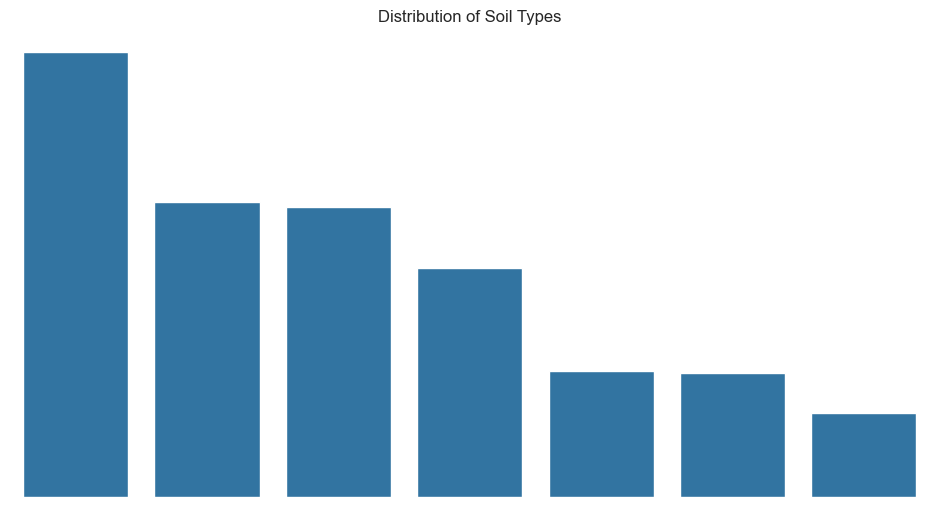

In [17]:
plt.figure(
    figsize=(10, 6)
)

sns.countplot(
    data=df,
    x="Soil_Type",
    order=df["Soil_Type"].value_counts().index
)

plt.title(
    "Distribution of Soil Types"
)

plt.xlabel(
    "Soil Type"
)

plt.ylabel(
    "Number of Records"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.savefig(
    "soil_type_distribution.png",
    dpi=404,
    bbox_inches="tight"
)
plt.axis(False)
plt.show()

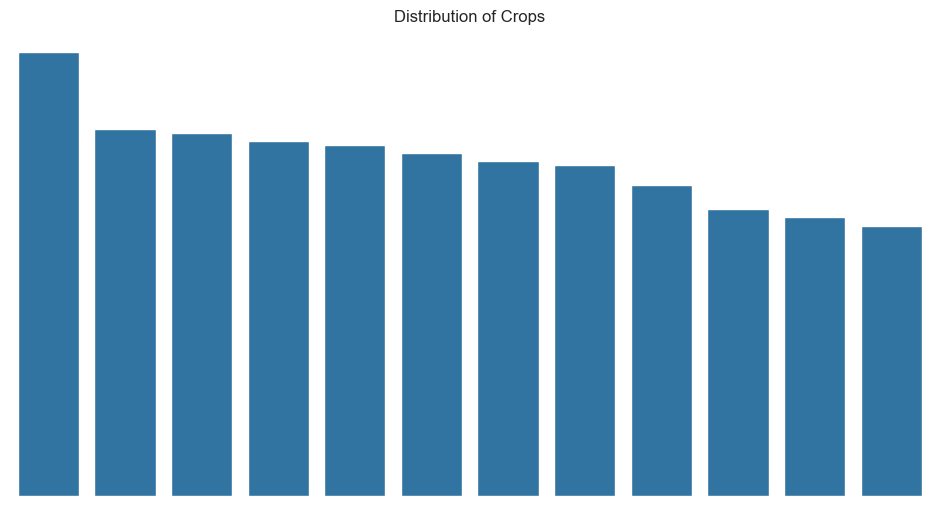

In [18]:
plt.figure(
    figsize=(10, 6)
)

sns.countplot(
    data=df,
    x="Crop",
    order=df["Crop"].value_counts().index
)

plt.title(
    "Distribution of Crops"
)

plt.xlabel(
    "Crop"
)

plt.ylabel(
    "Number of Records"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.savefig(
    "crop_distribution.png",
    dpi=404,
    bbox_inches="tight"
)
plt.axis(False)
plt.show()

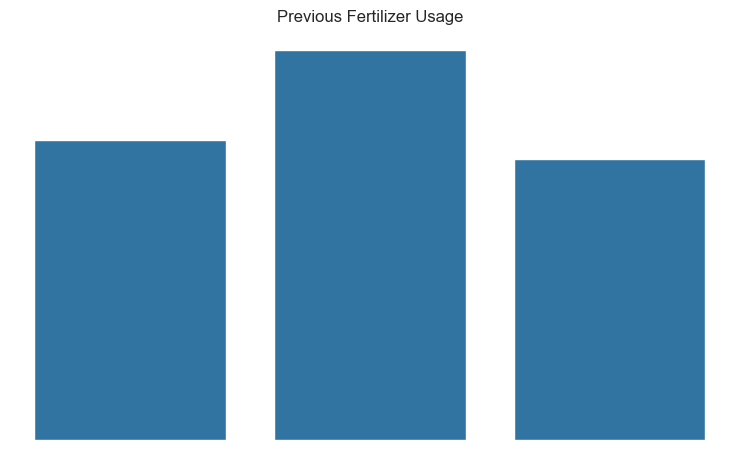

In [19]:
plt.figure(
    figsize=(8, 5)
)

sns.countplot(
    data=df,
    x="Previous_Fertilizer_Usage"
)

plt.title(
    "Previous Fertilizer Usage"
)

plt.xlabel(
    "Previous Fertilizer Usage"
)

plt.ylabel(
    "Number of Records"
)

plt.tight_layout()

plt.savefig(
    "previous_fertilizer_usage.png",
    dpi=404,
    bbox_inches="tight"
)
plt.axis(False)
plt.show()

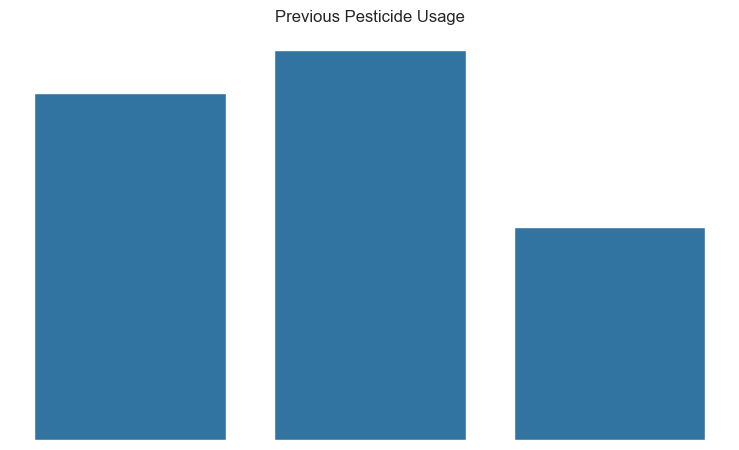

In [20]:
plt.figure(
    figsize=(8, 5)
)

sns.countplot(
    data=df,
    x="Previous_Pesticide_Usage"
)

plt.title(
    "Previous Pesticide Usage"
)

plt.xlabel(
    "Previous Pesticide Usage"
)

plt.ylabel(
    "Number of Records"
)

plt.tight_layout()

plt.savefig(
    "previous_pesticide_usage.png",
    dpi=404,
    bbox_inches="tight"
)
plt.axis(False)
plt.show()

In [21]:
# Select numerical columns

numeric_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns

correlation_matrix = df[
    numeric_columns
].corr()

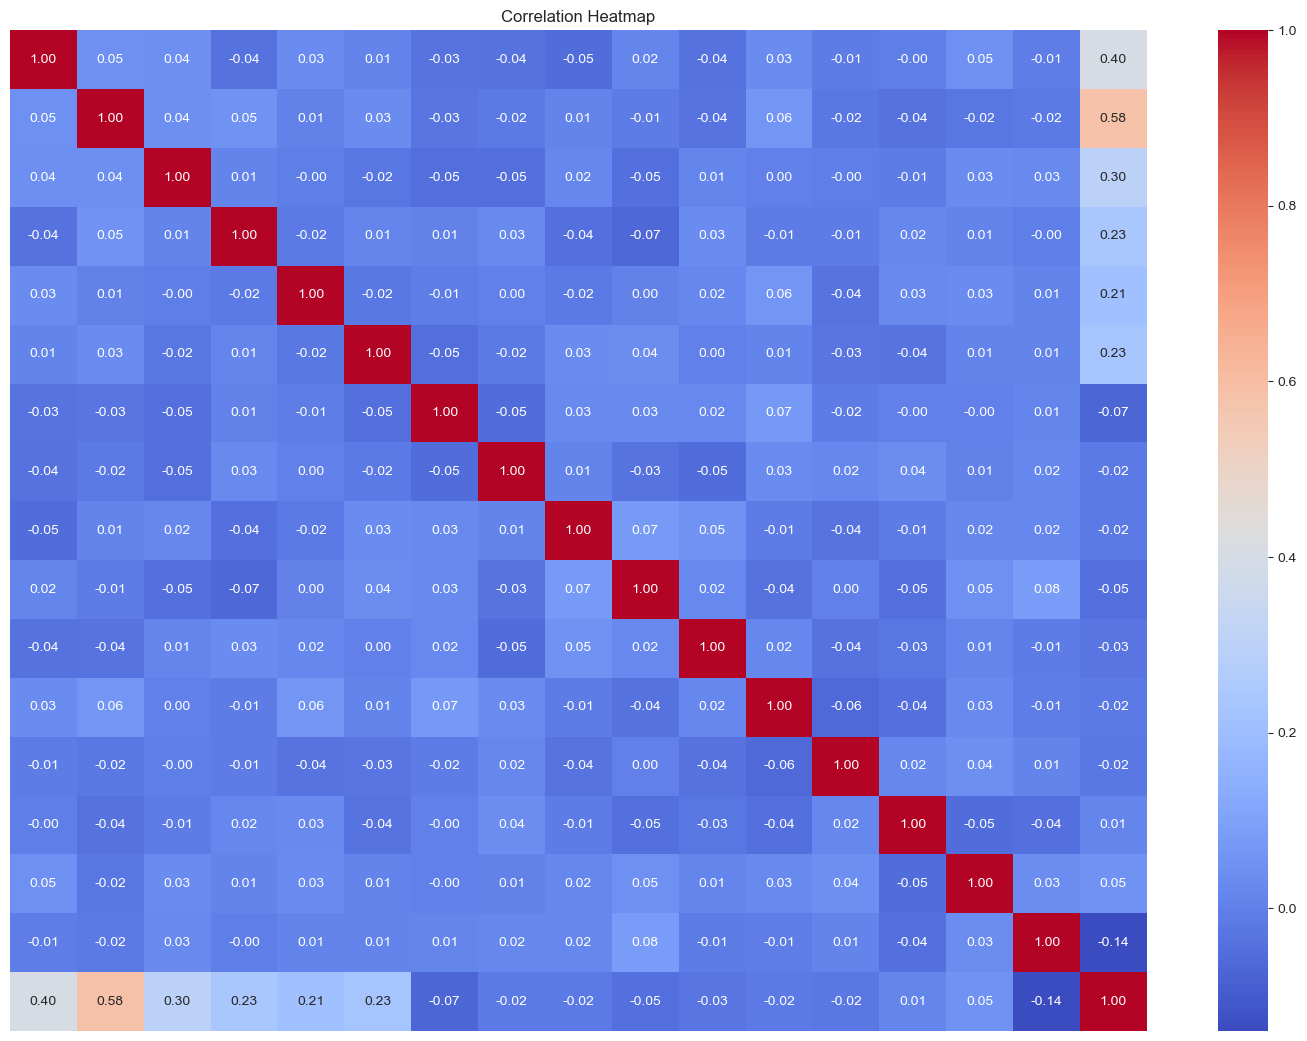

In [22]:
# Save Correlation Heatmap at 404 DPI

plt.figure(
    figsize=(16, 12)
)

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title(
    "Correlation Heatmap"
)

plt.tight_layout()

plt.savefig(
    "correlation_heatmap.png",
    dpi=404,
    bbox_inches="tight"
)
plt.axis(False)
plt.show()

In [23]:
# ============================================================
# CELL 6: DATA PREPROCESSING
# ============================================================

# Define target column

target_column = "Organic_Farming_Suitability"

print(
    "Target column:",
    target_column
)

Target column: Organic_Farming_Suitability


In [24]:
# Display target classes

print(
    df[target_column].value_counts()
)

Organic_Farming_Suitability
Not Suitable    577
Suitable        423
Name: count, dtype: int64


In [25]:
# Convert target into binary values

target_mapping = {
    "Suitable": 1,
    "Not Suitable": 0
}

y = df[target_column].map(
    target_mapping
)

print(
    y.value_counts()
)

Organic_Farming_Suitability
0    577
1    423
Name: count, dtype: int64


In [26]:
# Check whether target conversion created missing values

print(
    "Missing target values:",
    y.isnull().sum()
)

Missing target values: 0


In [27]:
# Create feature dataframe

X = df.drop(
    columns=[
        target_column,
        "Suitability_Score",
        "Sample_ID"
    ]
)

print(
    "Feature dataframe shape:",
    X.shape
)

Feature dataframe shape: (1000, 21)


In [28]:
# Display feature columns

print(
    "Features used by the ML models:"
)

for column in X.columns:
    print(column)

Features used by the ML models:
State
Soil_Type
Crop
pH
Organic_Carbon_pct
Available_N_kg_ha
Available_P_kg_ha
Available_K_kg_ha
Available_S_mg_kg
Available_Zn_mg_kg
Available_Fe_mg_kg
Available_Mn_mg_kg
Available_Cu_mg_kg
Available_B_mg_kg
EC_dS_m
Annual_Rainfall_mm
Mean_Temperature_C
Soil_Moisture_pct
Previous_Fertilizer_Usage
Previous_Pesticide_Usage
Years_Chemical_Input


In [29]:
# Identify numerical columns

numeric_features = X.select_dtypes(
    include=[
        "int64",
        "float64"
    ]
).columns.tolist()

print(
    "Numerical features:"
)

for column in numeric_features:
    print(column)

Numerical features:
pH
Organic_Carbon_pct
Available_N_kg_ha
Available_P_kg_ha
Available_K_kg_ha
Available_S_mg_kg
Available_Zn_mg_kg
Available_Fe_mg_kg
Available_Mn_mg_kg
Available_Cu_mg_kg
Available_B_mg_kg
EC_dS_m
Annual_Rainfall_mm
Mean_Temperature_C
Soil_Moisture_pct
Years_Chemical_Input


In [30]:
# Identify categorical columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print(
    "Categorical features:"
)

for column in categorical_features:
    print(column)

Categorical features:
State
Soil_Type
Crop
Previous_Fertilizer_Usage
Previous_Pesticide_Usage


In [31]:
# Split dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(
    "Training samples:",
    X_train.shape[0]
)

print(
    "Testing samples:",
    X_test.shape[0]
)

Training samples: 800
Testing samples: 200


In [32]:
# Numerical preprocessing

numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

In [33]:
# Combine preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_transformer,
            numeric_features
        ),
        (
            "categorical",
            categorical_transformer,
            categorical_features
        )
    ]
)

print(
    "Preprocessing pipeline created."
)

Preprocessing pipeline created.


In [34]:
# ============================================================
# CELL 7: LOGISTIC REGRESSION
# ============================================================

logistic_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

print(
    "Logistic Regression model created."
)

Logistic Regression model created.


In [35]:
# Train Logistic Regression

logistic_model.fit(
    X_train,
    y_train
)

print(
    "Logistic Regression training completed."
)

# Make predictions
y_pred_logistic = logistic_model.predict(
    X_test
)

y_prob_logistic = logistic_model.predict_proba(
    X_test
)[:, 1]

print(
    "Predictions completed."
)

Logistic Regression training completed.
Predictions completed.


In [36]:
# Logistic Regression metrics

logistic_accuracy = accuracy_score(
    y_test,
    y_pred_logistic
)

logistic_precision = precision_score(
    y_test,
    y_pred_logistic,
    zero_division=0
)

logistic_recall = recall_score(
    y_test,
    y_pred_logistic,
    zero_division=0
)

logistic_f1 = f1_score(
    y_test,
    y_pred_logistic,
    zero_division=0
)

logistic_auc = roc_auc_score(
    y_test,
    y_prob_logistic
)

print(
    "Logistic Regression Results"
)

print(
    "Accuracy:",
    logistic_accuracy
)

print(
    "Precision:",
    logistic_precision
)

print(
    "Recall:",
    logistic_recall
)

print(
    "F1 Score:",
    logistic_f1
)

print(
    "ROC-AUC:",
    logistic_auc
)

Logistic Regression Results
Accuracy: 0.805
Precision: 0.7875
Recall: 0.7411764705882353
F1 Score: 0.7636363636363637
ROC-AUC: 0.8891048593350382


In [37]:
print(
    classification_report(
        y_test,
        y_pred_logistic,
        target_names=[
            "Not Suitable",
            "Suitable"
        ]
    )
)

              precision    recall  f1-score   support

Not Suitable       0.82      0.85      0.83       115
    Suitable       0.79      0.74      0.76        85

    accuracy                           0.81       200
   macro avg       0.80      0.80      0.80       200
weighted avg       0.80      0.81      0.80       200



In [38]:
# ============================================================
# CELL 8: DECISION TREE
# ============================================================

decision_tree_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            DecisionTreeClassifier(
                random_state=42,
                max_depth=10
            )
        )
    ]
)

print(
    "Decision Tree model created."
)

# Train Decision Tree
decision_tree_model.fit(
    X_train,
    y_train
)

print(
    "Decision Tree training completed."
)

# Make predictions
y_pred_tree = decision_tree_model.predict(
    X_test
)

y_prob_tree = decision_tree_model.predict_proba(
    X_test
)[:, 1]

print(
    "Decision Tree predictions completed."
)

Decision Tree model created.
Decision Tree training completed.
Decision Tree predictions completed.


In [39]:
# Decision Tree metrics

tree_accuracy = accuracy_score(
    y_test,
    y_pred_tree
)

tree_precision = precision_score(
    y_test,
    y_pred_tree,
    zero_division=0
)

tree_recall = recall_score(
    y_test,
    y_pred_tree,
    zero_division=0
)

tree_f1 = f1_score(
    y_test,
    y_pred_tree,
    zero_division=0
)

tree_auc = roc_auc_score(
    y_test,
    y_prob_tree
)

print(
    "Decision Tree Results"
)

print(
    "Accuracy:",
    tree_accuracy
)

print(
    "Precision:",
    tree_precision
)

print(
    "Recall:",
    tree_recall
)

print(
    "F1 Score:",
    tree_f1
)

print(
    "ROC-AUC:",
    tree_auc
)

Decision Tree Results
Accuracy: 0.735
Precision: 0.686046511627907
Recall: 0.6941176470588235
F1 Score: 0.6900584795321637
ROC-AUC: 0.7296675191815857


In [40]:
print(
    classification_report(
        y_test,
        y_pred_tree,
        target_names=[
            "Not Suitable",
            "Suitable"
        ]
    )
)

              precision    recall  f1-score   support

Not Suitable       0.77      0.77      0.77       115
    Suitable       0.69      0.69      0.69        85

    accuracy                           0.73       200
   macro avg       0.73      0.73      0.73       200
weighted avg       0.74      0.73      0.74       200



In [41]:
# ============================================================
# CELL 9: K-NEAREST NEIGHBORS
# ============================================================

knn_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            KNeighborsClassifier(
                n_neighbors=5
            )
        )
    ]
)

print(
    "KNN model created."
)

# Train KNN
knn_model.fit(
    X_train,
    y_train
)

print(
    "KNN training completed."
)

# Make predictions
y_pred_knn = knn_model.predict(
    X_test
)

y_prob_knn = knn_model.predict_proba(
    X_test
)[:, 1]

print(
    "KNN predictions completed."
)

KNN model created.
KNN training completed.
KNN predictions completed.


In [42]:
# KNN metrics

knn_accuracy = accuracy_score(
    y_test,
    y_pred_knn
)

knn_precision = precision_score(
    y_test,
    y_pred_knn,
    zero_division=0
)

knn_recall = recall_score(
    y_test,
    y_pred_knn,
    zero_division=0
)

knn_f1 = f1_score(
    y_test,
    y_pred_knn,
    zero_division=0
)

knn_auc = roc_auc_score(
    y_test,
    y_prob_knn
)

print(
    "KNN Results"
)

print(
    "Accuracy:",
    knn_accuracy
)

print(
    "Precision:",
    knn_precision
)

print(
    "Recall:",
    knn_recall
)

print(
    "F1 Score:",
    knn_f1
)

print(
    "ROC-AUC:",
    knn_auc
)

print(
    classification_report(
        y_test,
        y_pred_knn,
        target_names=[
            "Not Suitable",
            "Suitable"
        ]
    )
)

KNN Results
Accuracy: 0.765
Precision: 0.7714285714285715
Recall: 0.6352941176470588
F1 Score: 0.6967741935483871
ROC-AUC: 0.8144245524296676
              precision    recall  f1-score   support

Not Suitable       0.76      0.86      0.81       115
    Suitable       0.77      0.64      0.70        85

    accuracy                           0.77       200
   macro avg       0.77      0.75      0.75       200
weighted avg       0.77      0.77      0.76       200



In [43]:
# ============================================================
# CELL 10: RANDOM FOREST
# ============================================================

random_forest_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                random_state=42,
                max_depth=12,
                n_jobs=-1
            )
        )
    ]
)

print(
    "Random Forest model created."
)

# Train Random Forest
random_forest_model.fit(
    X_train,
    y_train
)

print(
    "Random Forest training completed."
)

# Make predictions
y_pred_rf = random_forest_model.predict(
    X_test
)

y_prob_rf = random_forest_model.predict_proba(
    X_test
)[:, 1]

print(
    "Random Forest predictions completed."
)



Random Forest model created.
Random Forest training completed.
Random Forest predictions completed.


In [44]:
# Random Forest metrics
rf_accuracy = accuracy_score(
    y_test,
    y_pred_rf
)

rf_precision = precision_score(
    y_test,
    y_pred_rf,
    zero_division=0
)

rf_recall = recall_score(
    y_test,
    y_pred_rf,
    zero_division=0
)

rf_f1 = f1_score(
    y_test,
    y_pred_rf,
    zero_division=0
)

rf_auc = roc_auc_score(
    y_test,
    y_prob_rf
)

print(
    "Random Forest Results"
)

print(
    "Accuracy:",
    rf_accuracy
)

print(
    "Precision:",
    rf_precision
)

print(
    "Recall:",
    rf_recall
)

print(
    "F1 Score:",
    rf_f1
)

print(
    "ROC-AUC:",
    rf_auc
)

Random Forest Results
Accuracy: 0.78
Precision: 0.7662337662337663
Recall: 0.6941176470588235
F1 Score: 0.7283950617283951
ROC-AUC: 0.8853196930946292


In [45]:
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=[
            "Not Suitable",
            "Suitable"
        ]
    )
)

              precision    recall  f1-score   support

Not Suitable       0.79      0.84      0.82       115
    Suitable       0.77      0.69      0.73        85

    accuracy                           0.78       200
   macro avg       0.78      0.77      0.77       200
weighted avg       0.78      0.78      0.78       200



In [46]:
# ============================================================
# CELL 11: MODEL COMPARISON
# ============================================================

results = pd.DataFrame(
    {
        "Model": [
            "Logistic Regression",
            "Decision Tree",
            "KNN",
            "Random Forest"
        ],

        "Accuracy": [
            logistic_accuracy,
            tree_accuracy,
            knn_accuracy,
            rf_accuracy
        ],

        "Precision": [
            logistic_precision,
            tree_precision,
            knn_precision,
            rf_precision
        ],

        "Recall": [
            logistic_recall,
            tree_recall,
            knn_recall,
            rf_recall
        ],

        "F1 Score": [
            logistic_f1,
            tree_f1,
            knn_f1,
            rf_f1
        ],

        "ROC-AUC": [
            logistic_auc,
            tree_auc,
            knn_auc,
            rf_auc
        ]
    }
)

display(
    results
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.805,0.787500,0.741176,0.763636,0.889105
1,Decision Tree,0.735,0.686047,0.694118,0.690058,0.729668
2,KNN,0.765,0.771429,0.635294,0.696774,0.814425
3,Random Forest,0.780,0.766234,0.694118,0.728395,0.885320


In [47]:
# Sort models according to F1 Score

results_sorted = results.sort_values(
    by="F1 Score",
    ascending=False
)

display(
    results_sorted
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.805,0.787500,0.741176,0.763636,0.889105
3,Random Forest,0.780,0.766234,0.694118,0.728395,0.885320
2,KNN,0.765,0.771429,0.635294,0.696774,0.814425
1,Decision Tree,0.735,0.686047,0.694118,0.690058,0.729668


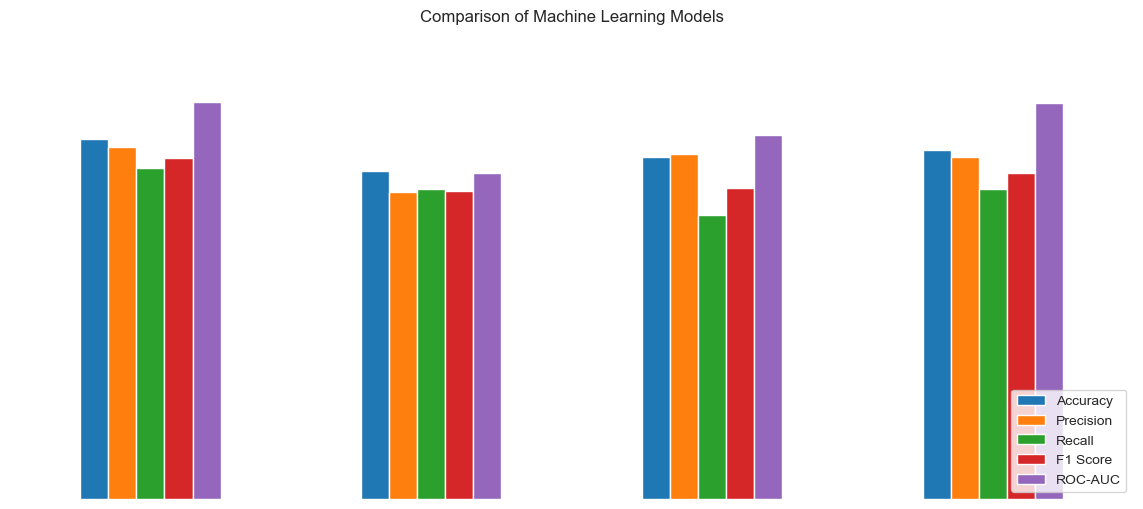

In [48]:
# Plot model comparison

results_plot = results.set_index(
    "Model"
)

ax = results_plot[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ]
].plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title(
    "Comparison of Machine Learning Models"
)

ax.set_xlabel(
    "Machine Learning Model"
)

ax.set_ylabel(
    "Score"
)

ax.set_ylim(
    0,
    1.05
)

ax.tick_params(
    axis="x",
    rotation=20
)

ax.legend(
    loc="lower right"
)

plt.tight_layout()

plt.savefig(
    "model_comparison.png",
    dpi=404,
    bbox_inches="tight"
)
plt.axis(False)
plt.show()

In [49]:
# ============================================================
# CELL 12: CONFUSION MATRICES
# ============================================================

cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic
)

cm_tree = confusion_matrix(
    y_test,
    y_pred_tree
)

cm_knn = confusion_matrix(
    y_test,
    y_pred_knn
)

cm_rf = confusion_matrix(
    y_test,
    y_pred_rf
)

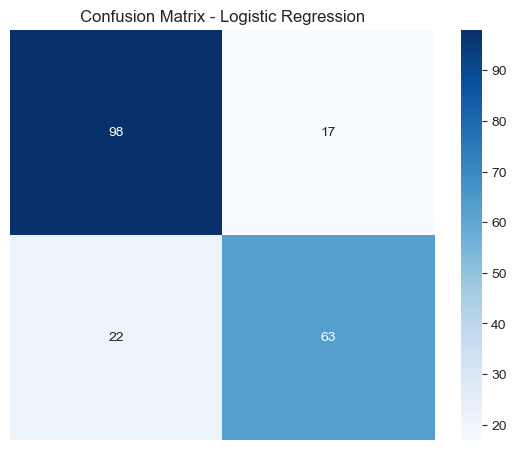

In [50]:
plt.figure(
    figsize=(6, 5)
)

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0,
    xticklabels=[
        "Not Suitable",
        "Suitable"
    ],
    yticklabels=[
        "Not Suitable",
        "Suitable"
    ]
)

plt.title(
    "Confusion Matrix - Logistic Regression"
)

plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "Actual Label"
)

plt.tight_layout()

plt.savefig(
    "confusion_matrix_logistic.png",
    dpi=404,
    bbox_inches="tight"
)
plt.axis(False)
plt.show()

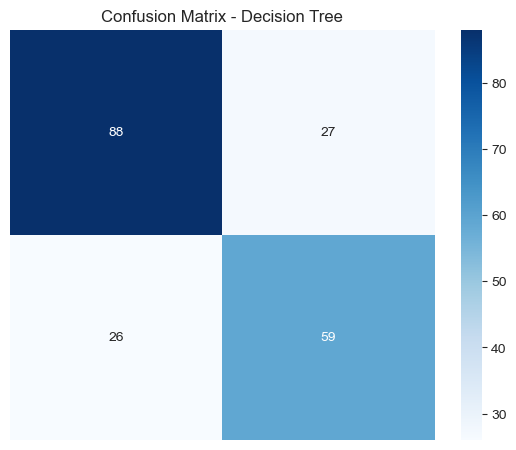

In [51]:
plt.figure(
    figsize=(6, 5)
)

sns.heatmap(
    cm_tree,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0,
    xticklabels=[
        "Not Suitable",
        "Suitable"
    ],
    yticklabels=[
        "Not Suitable",
        "Suitable"
    ]
)

plt.title(
    "Confusion Matrix - Decision Tree"
)

plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "Actual Label"
)

plt.tight_layout()

plt.savefig(
    "confusion_matrix_decision_tree.png",
    dpi=404,
    bbox_inches="tight"
)
plt.axis(False)
plt.show()

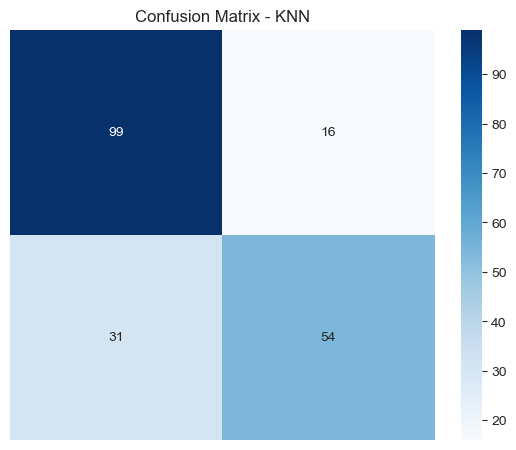

In [52]:
plt.figure(
    figsize=(6, 5)
)

sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Not Suitable",
        "Suitable"
    ],
    yticklabels=[
        "Not Suitable",
        "Suitable"
    ]
)

plt.title(
    "Confusion Matrix - KNN"
)

plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "Actual Label"
)
plt.savefig(
    "confusion_matrix_knn.png",
    dpi=404,
    bbox_inches="tight"
)

plt.tight_layout()
plt.axis(False)
plt.show()

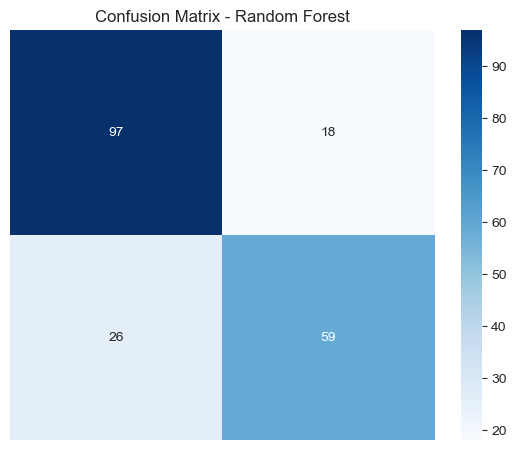

In [53]:
plt.figure(
    figsize=(6, 5)
)

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Not Suitable",
        "Suitable"
    ],
    yticklabels=[
        "Not Suitable",
        "Suitable"
    ]
)

plt.title(
    "Confusion Matrix - Random Forest"
)

plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "Actual Label"
)
plt.savefig(
    "confusion_matrix_random_forest.png",
    dpi=404,
    bbox_inches="tight"
)

plt.tight_layout()
plt.axis(False)
plt.show()

In [54]:
# ============================================================
# CELL 13: ROC CURVES
# ============================================================

fpr_logistic, tpr_logistic, _ = roc_curve(
    y_test,
    y_prob_logistic
)

fpr_tree, tpr_tree, _ = roc_curve(
    y_test,
    y_prob_tree
)

fpr_knn, tpr_knn, _ = roc_curve(
    y_test,
    y_prob_knn
)

fpr_rf, tpr_rf, _ = roc_curve(
    y_test,
    y_prob_rf
)

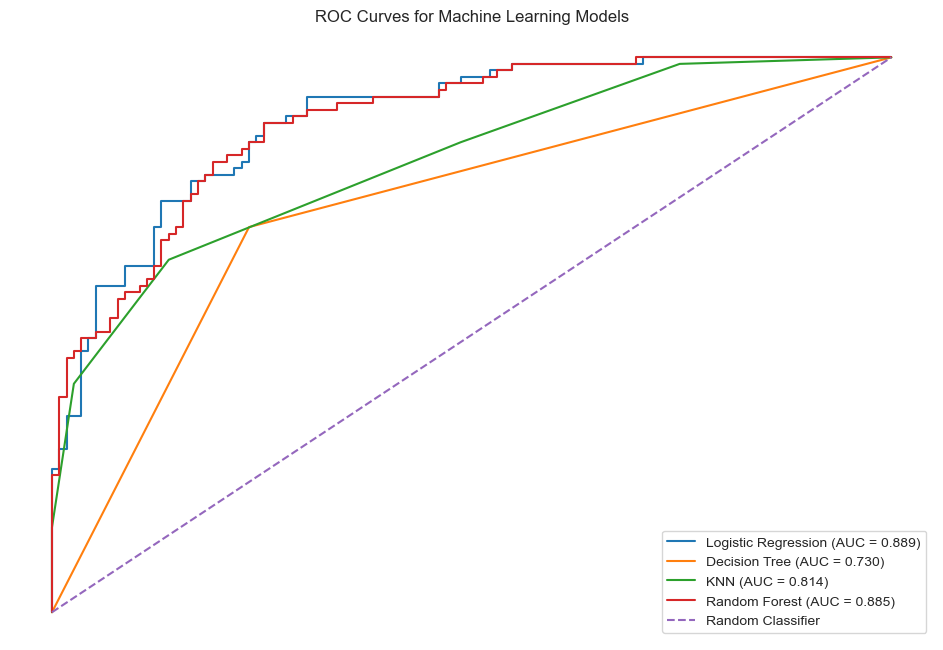

In [55]:
plt.figure(
    figsize=(10, 7)
)

plt.plot(
    fpr_logistic,
    tpr_logistic,
    label=f"Logistic Regression (AUC = {logistic_auc:.3f})"
)

plt.plot(
    fpr_tree,
    tpr_tree,
    label=f"Decision Tree (AUC = {tree_auc:.3f})"
)

plt.plot(
    fpr_knn,
    tpr_knn,
    label=f"KNN (AUC = {knn_auc:.3f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {rf_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title(
    "ROC Curves for Machine Learning Models"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.legend()

plt.grid(
    True
)
plt.savefig(
    "roc_curves_all_models.png",
    dpi=404,
    bbox_inches="tight"
)
plt.tight_layout()
plt.axis(False)
plt.show()

In [56]:
# ============================================================
# CELL 14: FEATURE IMPORTANCE
# ============================================================

# Get trained Random Forest classifier

rf_classifier = random_forest_model.named_steps[
    "classifier"
]

# Get preprocessing object

rf_preprocessor = random_forest_model.named_steps[
    "preprocessor"
]

In [57]:
# Get transformed feature names

feature_names = (
    rf_preprocessor
    .get_feature_names_out()
)

print(
    "Number of transformed features:",
    len(feature_names)
)

Number of transformed features: 56


In [58]:
# Get feature importance values

feature_importances = (
    rf_classifier
    .feature_importances_
)

feature_importance_df = pd.DataFrame(
    {
        "Feature": feature_names,
        "Importance": feature_importances
    }
)

feature_importance_df = (
    feature_importance_df
    .sort_values(
        by="Importance",
        ascending=False
    )
)

display(
    feature_importance_df.head(20)
)

,Feature,Importance
1,numeric__Organic_Carbon_pct,0.199305
0,numeric__pH,0.095392
2,numeric__Available_N_kg_ha,0.075802
3,numeric__Available_P_kg_ha,0.054796
5,numeric__Available_S_mg_kg,0.052332
4,numeric__Available_K_kg_ha,0.046905
8,numeric__Available_Mn_mg_kg,0.034203
14,numeric__Soil_Moisture_pct,0.033871
12,numeric__Annual_Rainfall_mm,0.032383
10,numeric__Available_B_mg_kg,0.031309


In [59]:
# Get feature importance values

feature_importances = (
    rf_classifier
    .feature_importances_
)

feature_importance_df = pd.DataFrame(
    {
        "Feature": feature_names,
        "Importance": feature_importances
    }
)

feature_importance_df = (
    feature_importance_df
    .sort_values(
        by="Importance",
        ascending=False
    )
)

display(
    feature_importance_df.head(20)
)

,Feature,Importance
1,numeric__Organic_Carbon_pct,0.199305
0,numeric__pH,0.095392
2,numeric__Available_N_kg_ha,0.075802
3,numeric__Available_P_kg_ha,0.054796
5,numeric__Available_S_mg_kg,0.052332
4,numeric__Available_K_kg_ha,0.046905
8,numeric__Available_Mn_mg_kg,0.034203
14,numeric__Soil_Moisture_pct,0.033871
12,numeric__Annual_Rainfall_mm,0.032383
10,numeric__Available_B_mg_kg,0.031309


In [60]:
# Plot top 15 important features

top_features = (
    feature_importance_df
    .head(15)
    .sort_values(
        by="Importance"
    )
)

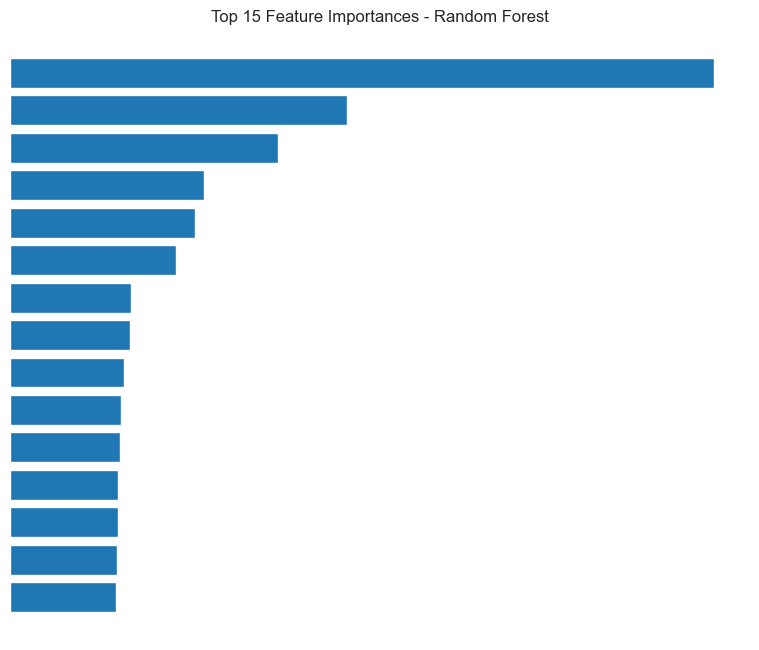

In [61]:
plt.figure(
    figsize=(10, 7)
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title(
    "Top 15 Feature Importances - Random Forest"
)

plt.xlabel(
    "Importance"
)

plt.ylabel(
    "Feature"
)
plt.savefig(
    "top_15_feature_importance_random_forest.png",
    dpi=404,
    bbox_inches="tight"
)
plt.tight_layout()
plt.axis(False)
plt.show()

In [62]:
# ============================================================
# CELL 15: BEST MODEL SELECTION
# ============================================================


# ------------------------------------------------------------
# Find the best model based on F1 Score
# ------------------------------------------------------------

best_model_name = results.loc[
    results["F1 Score"].idxmax(),
    "Model"
]

print(
    "Best model based on F1 Score:"
)

print(
    best_model_name
)


# ------------------------------------------------------------
# Find the best model based on ROC-AUC
# ------------------------------------------------------------

best_auc_model = results.loc[
    results["ROC-AUC"].idxmax(),
    "Model"
]

print(
    "Best model based on ROC-AUC:"
)

print(
    best_auc_model
)


# ------------------------------------------------------------
# Find the best model based on Accuracy
# ------------------------------------------------------------

best_accuracy_model = results.loc[
    results["Accuracy"].idxmax(),
    "Model"
]

print(
    "Best model based on Accuracy:"
)

print(
    best_accuracy_model
)


# ------------------------------------------------------------
# Display complete model ranking
# ------------------------------------------------------------

print(
    "Complete model ranking:"
)

display(
    results_sorted
)


# ------------------------------------------------------------
# Create dictionary of trained models
# ------------------------------------------------------------

model_dictionary = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "KNN": knn_model,
    "Random Forest": random_forest_model
}


# ------------------------------------------------------------
# Select the best trained model
# ------------------------------------------------------------

best_model = model_dictionary[
    best_model_name
]


# ------------------------------------------------------------
# Display selected model
# ------------------------------------------------------------

print(
    "Best trained model selected successfully:"
)

print(
    best_model_name
)

Best model based on F1 Score:
Logistic Regression
Best model based on ROC-AUC:
Logistic Regression
Best model based on Accuracy:
Logistic Regression
Complete model ranking:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.805,0.787500,0.741176,0.763636,0.889105
3,Random Forest,0.780,0.766234,0.694118,0.728395,0.885320
2,KNN,0.765,0.771429,0.635294,0.696774,0.814425
1,Decision Tree,0.735,0.686047,0.694118,0.690058,0.729668


Best trained model selected successfully:
Logistic Regression


In [63]:
# ============================================================
# CELL 16: SAVE BEST MODEL
# ============================================================


# ------------------------------------------------------------
# Import joblib
# ------------------------------------------------------------

import joblib


# ------------------------------------------------------------
# Set model file name
# ------------------------------------------------------------

model_file = (
    "best_organic_farming_model.pkl"
)


# ------------------------------------------------------------
# Save the best trained model
# ------------------------------------------------------------

joblib.dump(
    best_model,
    model_file
)


# ------------------------------------------------------------
# Confirmation message
# ------------------------------------------------------------

print(
    "Model saved successfully."
)

print(
    "File name:",
    model_file
)

Model saved successfully.
File name: best_organic_farming_model.pkl


In [64]:
# Save model comparison results
results_file = (
    "model_comparison_results.csv"
)

results.to_csv(
    results_file,
    index=False
)

print(
    "Model comparison results saved."
)

print(
    "File name:",
    results_file
)

Model comparison results saved.
File name: model_comparison_results.csv


In [65]:
# Save feature importance
feature_importance_file = (
    "feature_importance_results.csv"
)

feature_importance_df.to_csv(
    feature_importance_file,
    index=False
)

print(
    "Feature importance saved."
)

Feature importance saved.


In [66]:
# ============================================================
# CELL 17: NEW PREDICTION
# ============================================================

# Create a new sample

new_data = pd.DataFrame(
    {
        "State": [
            "West Bengal"
        ],

        "Soil_Type": [
            "Alluvial"
        ],

        "Crop": [
            "Rice"
        ],

        "pH": [
            6.5
        ],

        "Organic_Carbon_pct": [
            0.80
        ],

        "Available_N_kg_ha": [
            180
        ],

        "Available_P_kg_ha": [
            25
        ],

        "Available_K_kg_ha": [
            150
        ],

        "Available_S_mg_kg": [
            15
        ],

        "Available_Zn_mg_kg": [
            1.5
        ],

        "Available_Fe_mg_kg": [
            10
        ],

        "Available_Mn_mg_kg": [
            8
        ],

        "Available_Cu_mg_kg": [
            0.8
        ],

        "Available_B_mg_kg": [
            0.6
        ],

        "EC_dS_m": [
            0.5
        ],

        "Annual_Rainfall_mm": [
            1400
        ],

        "Mean_Temperature_C": [
            26
        ],

        "Soil_Moisture_pct": [
            45
        ],

        "Previous_Fertilizer_Usage": [
            "Low"
        ],

        "Previous_Pesticide_Usage": [
            "Low"
        ],

        "Years_Chemical_Input": [
            2
        ]
    }
)

display(
    new_data
)

,State,Soil_Type,Crop,pH,Organic_Carbon_pct,Available_N_kg_ha,Available_P_kg_ha,Available_K_kg_ha,Available_S_mg_kg,Available_Zn_mg_kg,...,Available_Mn_mg_kg,Available_Cu_mg_kg,Available_B_mg_kg,EC_dS_m,Annual_Rainfall_mm,Mean_Temperature_C,Soil_Moisture_pct,Previous_Fertilizer_Usage,Previous_Pesticide_Usage,Years_Chemical_Input
0,West Bengal,Alluvial,Rice,6.5,0.8,180,25,150,15,1.5,...,8,0.8,0.6,0.5,1400,26,45,Low,Low,2


In [67]:
# Check that new data has exactly the same columns

print(
    "New data columns:"
)

print(
    new_data.columns.tolist()
)

New data columns:
['State', 'Soil_Type', 'Crop', 'pH', 'Organic_Carbon_pct', 'Available_N_kg_ha', 'Available_P_kg_ha', 'Available_K_kg_ha', 'Available_S_mg_kg', 'Available_Zn_mg_kg', 'Available_Fe_mg_kg', 'Available_Mn_mg_kg', 'Available_Cu_mg_kg', 'Available_B_mg_kg', 'EC_dS_m', 'Annual_Rainfall_mm', 'Mean_Temperature_C', 'Soil_Moisture_pct', 'Previous_Fertilizer_Usage', 'Previous_Pesticide_Usage', 'Years_Chemical_Input']


In [68]:
# Make prediction

new_prediction = best_model.predict(
    new_data
)

print(
    "Numeric prediction:"
)

print(
    new_prediction
)

Numeric prediction:
[0]


In [69]:
# Convert prediction to readable result

if new_prediction[0] == 1:

    prediction_result = "Suitable"

else:

    prediction_result = "Not Suitable"

print(
    "Organic Farming Suitability Prediction:"
)

print(
    prediction_result
)

Organic Farming Suitability Prediction:
Not Suitable


In [70]:
# Prediction probability

new_probability = (
    best_model
    .predict_proba(new_data)
)

print(
    "Probability of Not Suitable:",
    new_probability[0][0]
)

print(
    "Probability of Suitable:",
    new_probability[0][1]
)

Probability of Not Suitable: 0.747546035547618
Probability of Suitable: 0.25245396445238194


In [71]:
# Final prediction report

print(
    "=========================================="
)

print(
    " ORGANIC FARMING SUITABILITY PREDICTION"
)

print(
    "=========================================="
)

print(
    "Prediction:",
    prediction_result
)

print(
    "Not Suitable Probability:",
    f"{new_probability[0][0] * 100:.2f}%"
)

print(
    "Suitable Probability:",
    f"{new_probability[0][1] * 100:.2f}%"
)

print(
    "=========================================="
)

 ORGANIC FARMING SUITABILITY PREDICTION
Prediction: Not Suitable
Not Suitable Probability: 74.75%
Suitable Probability: 25.25%
